In [1]:
#Данный ноутбук использует данные, подготовленные в файле 01_data_exploration.ipynb, загруженные в базу PostgreSQL
%pip install sqlalchemy psycopg2-binary

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
%pip install python-dotenv

  Obtaining dependency information for python-dotenv from https://files.pythonhosted.org/packages/60/d1/38f3a3405989a89ac18390803e70c6ad7c7760da4f9b83cbeca0c44a0c72/python_dotenv-1.2.4-py3-none-any.whl.metadata
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install "psycopg[binary]"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import os
from pathlib import Path
from dotenv import load_dotenv

# Находим корневую папку проекта и загружаем .env
project_path = Path.cwd().parent
load_dotenv(project_path / ".env")

# Получаем параметры подключения
db_user = os.getenv("DB_USER")
db_password = os.getenv("DB_PASSWORD")
db_host = os.getenv("DB_HOST")
db_port = os.getenv("DB_PORT")
db_name = os.getenv("DB_NAME")

In [18]:
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

# Формируем подключение к PostgreSQL из параметров .env
connection_url = URL.create(
    drivername="postgresql+psycopg2",
    username=db_user,
    password=db_password,
    host=db_host,
    port=int(db_port),
    database=db_name
)

engine = create_engine(connection_url)

In [19]:
# Проверяем подключение к PostgreSQL
with engine.connect() as connection:
    print("Подключение к PostgreSQL успешно!")

Подключение к PostgreSQL успешно!


In [20]:
import pandas as pd
from sqlalchemy import create_engine

engine

df_months = pd.read_sql('SELECT "month", sum("Revenue") as "Revenue" FROM sales GROUP BY "month" ORDER BY "Revenue" DESC', engine)
print(df_months)

      month      Revenue
0   2011-11  1503866.780
1   2011-10  1151263.730
2   2011-09  1056435.192
3   2010-12   821452.730
4   2011-05   769296.610
5   2011-06   760547.010
6   2011-08   757841.380
7   2011-07   718076.121
8   2011-03   716215.260
9   2011-01   689811.610
10  2011-12   637790.330
11  2011-04   536968.491
12  2011-02   522545.560


In [2]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


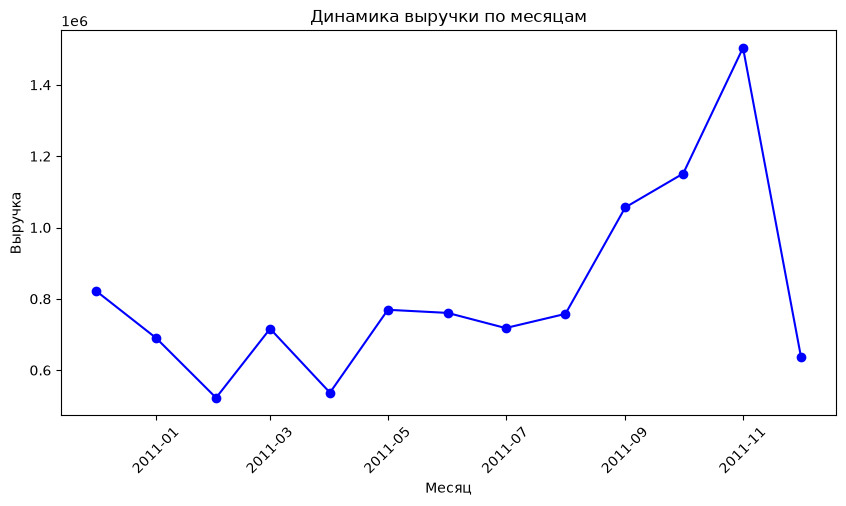

In [21]:
import pandas as pd
from sqlalchemy import create_engine
import matplotlib.pyplot as plt

engine

df_months = pd.read_sql('SELECT "month", sum("Revenue") as "Revenue" FROM sales GROUP BY "month"', engine)

df_months['month'] = pd.to_datetime(df_months['month'])
df_months = df_months.sort_values('month')

plt.figure(figsize=(10, 5))
plt.plot(df_months['month'], df_months['Revenue'], marker='o', color='blue')
plt.title('Динамика выручки по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Выручка')
plt.xticks(rotation=45)
plt.savefig('../reports/plot_months.png', dpi=300, bbox_inches='tight')
plt.show()

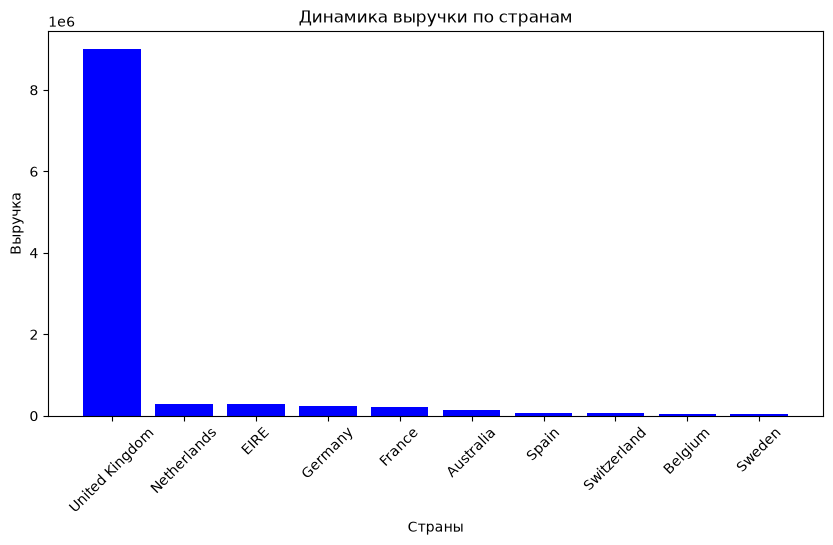

In [22]:
import pandas as pd
from sqlalchemy import create_engine
import matplotlib.pyplot as plt

engine

df_countries = pd.read_sql('select "Country", sum("Revenue") as "Revenue" from sales group by "Country" order by "Revenue" DESC limit 10;', engine)

plt.figure(figsize=(10, 5))
plt.bar(df_countries['Country'], df_countries['Revenue'], color='blue')
plt.title('Динамика выручки по странам')
plt.xlabel('Страны')
plt.ylabel('Выручка')
plt.xticks(rotation=45)
plt.savefig('../reports/plot_сountry.png', dpi=300, bbox_inches='tight')
plt.show()

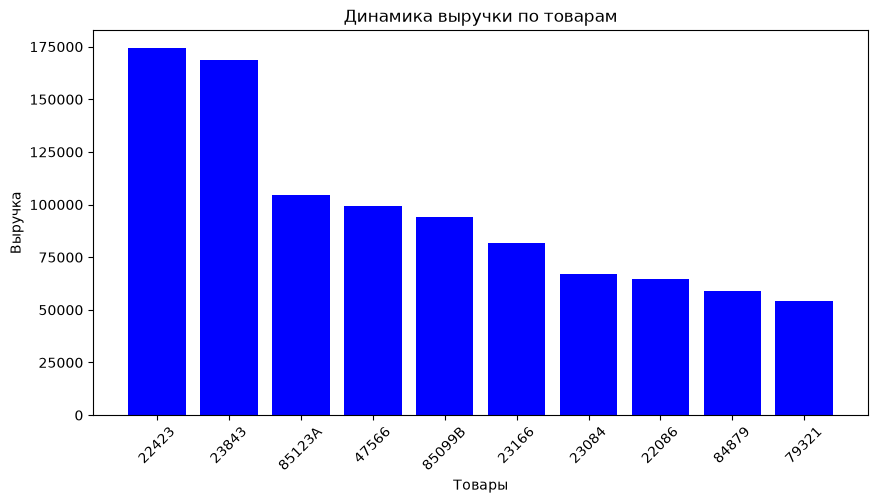

In [23]:
import pandas as pd
from sqlalchemy import create_engine
import matplotlib.pyplot as plt

engine

df_products = pd.read_sql('''select "StockCode", sum("Revenue") as "Revenue" from sales where "StockCode" != 'DOT' and "StockCode" != 'POST' and "StockCode" != 'M' group by "StockCode" order by "Revenue" desc limit 10;''', engine)

plt.figure(figsize=(10, 5))
plt.bar(df_products['StockCode'], df_products['Revenue'], color='blue')
plt.title('Динамика выручки по товарам')
plt.xlabel('Товары')
plt.ylabel('Выручка')
plt.xticks(rotation=45)
plt.savefig('../reports/plot_products.png', dpi=300, bbox_inches='tight')
plt.show()